agent

tools
1. getTheFiles() => get our github repository
2. getFileContent()
3. postComments()


ReAct pattern


In [9]:
import os
import json
import requests
from typing import TypedDict, Annotated, List, Literal
from dotenv import load_dotenv
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from pydantic import BaseModel, Field

In [10]:
load_dotenv()

GITHUB_TOKEN = os.getenv("GITHUB_TOKEN")
GITHUB_REPO  = "rahul8879/e-comm-agentic-demo"
HEADERS = {
    "Authorization": f"token {GITHUB_TOKEN}",
    "Accept": "application/vnd.github.v3+json"
}
BASE_URL = f"https://api.github.com/repos/{GITHUB_REPO}"

llm = ChatOpenAI(model="gpt-4o", temperature=0)

r = requests.get(BASE_URL, headers=HEADERS)
print(f"Repo: {r.json().get('full_name')}")
print(f"Status: {r.status_code}")

Repo: None
Status: 401


In [11]:
pr_number=13

In [20]:
from langchain_core.tools import tool
@tool
def get_pr_details() -> dict:
    """Fetch PR title, description, author, and current status."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}"
    r = requests.get(url, headers=HEADERS)
    pr = r.json()
    return {
        "title":       pr.get("title"),
        "description": pr.get("body", "No description provided"),
        "author":      pr["user"]["login"],
        "state":       pr.get("state"),
        "branch":      pr["head"]["ref"],
    }

In [ ]:

@tool
def get_pr_files() -> list:
    """List all files changed in the PR with their status and patch."""
    url = f"{BASE_URL}/pulls/{PR_NUMBER}/files"
    r = requests.get(url, headers=HEADERS)
    files = []
    for f in r.json():
        files.append({
            "filename": f.get("filename"),
            "status":   f.get("status"),       # added / modified / removed
            "changes":  f.get("changes"),
            "patch":    f.get("patch", "")[:2000],  # limit patch size
        })
    return files

In [15]:
@tool
def get_file_content(file_path: str) -> str:
    """Fetch the full content of a file from the repo's default branch."""
    url = f"{BASE_URL}/contents/{file_path}"
    r = requests.get(url, headers=HEADERS)
    data = r.json()
    if "content" not in data:
        return f"Could not fetch: {file_path}"
    return base64.b64decode(data["content"]).decode("utf-8")

In [16]:
@tool
def post_pr_comment(comment: str) -> dict:
    """Post a review comment on the PR."""
    url = f"{BASE_URL}/issues/{PR_NUMBER}/comments"
    payload = {"body": comment}
    r = requests.post(url, headers=HEADERS, json=payload)
    return {"status": r.status_code, "comment_url": r.json().get("html_url")}


In [21]:
get_pr_files.invoke()

TypeError: BaseTool.invoke() missing 1 required positional argument: 'input'

In [18]:
# AST parser: learn about it 

In [22]:
tools=[get_pr_details,get_pr_files,get_file_content,post_pr_comment]

In [23]:
# step1 : define agent's state
class State(TypedDict):
    messages : Annotated[list, add_messages]
    pr_number : int
    verdict : str

In [24]:
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
llm_with_tools = llm.bind_tools(tools)

In [ ]:
SYSTEM_PROMPT = """You are CodeSentinel — an expert PR code reviewer.

Always post a comment in this format:
## 🤖 CodeSentinel Review

### ✅ What looks good
- ...

### ⚠️ Issues Found
- ...

### 🔧 Suggestions
- ...

### 📊 Verdict
APPROVED / NEEDS CHANGES

For posting the comment please use the tools provided to you
You are free to post the comment use the tool: post_pr_comment for it
"""



In [26]:
# agent model, instruction, tools
def agent_node(state: State)->State:
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


In [27]:
# condition function to decide the next node to be
def should_continue(state: State)-> str:
    last = state["messages"][-1]
    if hasattr(last, "tool_calls") and last.tool_calls:
        return "tools"
    return "end"

In [29]:
from langgraph.prebuilt import ToolNode
# tools as node
tool_node = ToolNode(tools)


In [ ]:
#step 3 build graph and add nodes, edges etc
graph_builder = StateGraph(State)
graph_builder.add_node("agent", agent_node)
graph_builder.add_node("tools", tool_node)

graph_builder.add_edge(START, "agent") 

graph_builder.add_conditional_edges("agent",should_continue,{"tools": "tools","end": END})

graph_builder.add_edge("tools", "agent") 



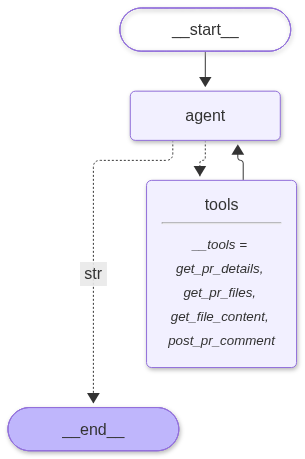

In [31]:
#step 4 compile the graph
graph = graph_builder.compile()
graph

In [ ]:
PR_NUMBER=10

In [ ]:
initial_state = {
    "messages": [HumanMessage(content=f"Review PR #{PR_NUMBER}")],
    "pr_number": PR_NUMBER,
    "verdict":   "",
}

result = graph.invoke(initial_state)

In [ ]:
result

# for write operations our agent needs to have some go ahead with us as they are always very good to go for read operations, but write ones it should be very 

# also when the verdict is need changes then only it will raise PR

In [ ]:
final_review = result["messages"][-1].content
print(final_review)

one agent _> with too much contexts

too many-> with little or not context

both willl cause issue?

is it right understanding

 
solution

usecase thinking

how many agents needed

create multiple groups with sensible 

not too many tools